In [2]:
import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
#https://huggingface.co/datasets/swami93/indian-names-1.5M

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

cuda
Tesla T4


In [4]:
import os

# List all files under the input directory
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/eluriadarsh/names-dataset/names_dataset.txt


In [5]:
with open("/kaggle/input/datasets/eluriadarsh/names-dataset/names_dataset.txt") as f:
    words = f.read().split("\n")


In [6]:
len(words)

114240

In [7]:
allwords =[]
for w in words:
    w = w.split(" ")
    # print(w, len(w))

    if len(w) == 2:
        allwords.append(w[1])
words = allwords

In [8]:
len(words)

114239

In [9]:
chars = sorted(list(set("".join(words))))

stoi = {s:i+1 for i,s in enumerate(chars)}
stoi["."] = 0

itos = {i:k for k, i in stoi.items()}
vocab_size = len(itos)
print(vocab_size)

27


In [10]:
block_size = 8

def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0]*block_size
        for ch in w+".":
            X.append(context)
            Y.append(stoi[ch])

            context = context[1:] + [stoi[ch]]
    X, Y = torch.tensor(X), torch.tensor(Y)

    return X, Y

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xts, Yts = build_dataset(words[n2:])

len(Xtr), len(Xdev), len(Xts)

(813749, 102046, 101099)

In [11]:
Xtr = Xtr.to(device)
Ytr = Ytr.to(device)
Xdev = Xdev.to(device)
Ydev = Ydev.to(device)
Xts = Xts.to(device)
Yts = Yts.to(device)

In [12]:
Xtr[:5], Ytr[:5]

(tensor([[ 0,  0,  0,  0,  0,  0,  0,  0],
         [ 0,  0,  0,  0,  0,  0,  0, 20],
         [ 0,  0,  0,  0,  0,  0, 20,  8],
         [ 0,  0,  0,  0,  0, 20,  8,  9],
         [ 0,  0,  0,  0, 20,  8,  9, 22]], device='cuda:0'),
 tensor([20,  8,  9, 22,  0], device='cuda:0'))

In [13]:
class Sequential:
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        params = [p for layer in self.layers for p in layer.parameters()]
        return params

class Embedding:
    def __init__(self, num_embeddings, embeddings_size):
        self.weight = torch.randn((num_embeddings, embeddings_size))

    def __call__(self, ix):
        self.out = self.weight[ix]
        # print(f"Embedding layer: {self.out.shape}")
        return self.out

    def parameters(self):
        return [self.weight]


class Flatten:
    def __init__(self, n):
        self.n = n

    def __call__(self, x):
        batch_size, block_size, n_emb = x.shape

        x = x.view(batch_size, block_size//self.n, n_emb*self.n)

        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        # print(f"Flatten layer: {self.out.shape}")
        return self.out

    def parameters(self):
        return []


class Linear:
    def __init__(self, fanin, fanout, bias=True):
        self.weight = torch.randn((fanin, fanout)) / (fanin**0.5)
        self.bias = torch.randn(fanout) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight

        if self.bias is not None:
            self.out += self.bias

        # print(f"Linear layer: {self.out.shape}")
        return self.out

    def parameters(self):
        return [self.weight] + ([self.bias] if self.bias is not None else [])


class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True

        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            dim = None
            if x.dim() == 2:
                dim = 0
            elif x.dim() == 3:
                dim = (0,1)

            xmean = x.mean(dim, keepdim=True)
            xvar = x.var(dim, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var

        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        self.out = self.gamma * xhat + self.beta

        with torch.no_grad():
            if self.training:
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar

        # print(f"Batch Norm layer: {self.out.shape}")
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        # print(f"TanH layer: {self.out.shape}")
        return self.out
    def parameters(self):
        return []

In [14]:
n_emb = 50
n_hidden = 300
batch_size = 32

model = Sequential([
    Embedding(vocab_size, n_emb),
    Flatten(2), Linear(n_emb*2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Flatten(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Flatten(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size)
])

# model.to(device)

with torch.no_grad():
    model.layers[-1].weight *= 0.1

for layer in model.layers:
    if isinstance(layer, BatchNorm1d):
        layer.running_mean = layer.running_mean.to(device)
        layer.running_var = layer.running_var.to(device)

for p in model.parameters():
    p.data = p.data.to(device)
    p.requires_grad = True

n_params = [p.nelement() for p in model.parameters()]
print(sum(n_params))

401277


In [15]:
epoch = 200000
lossi = []

for i in range(epoch):
    ind = torch.randint(0, len(Xtr), (batch_size, ), device=device)
    x, y = Xtr[ind], Ytr[ind]
    # print(x.shape)

    logits = model(x)

    loss = F.cross_entropy(logits, y)

    for p in model.parameters():
        p.grad = None

    loss.backward()

    lr = 0.1 if i < epoch//2 else 0.01
    for p in model.parameters():
        p.data -= lr * p.grad

    if i%10000 == 0:
        print(f"epoch: {i}, loss:{loss.item()}")

    lossi.append(loss.log10().item())
    # break

epoch: 0, loss:3.952047109603882
epoch: 10000, loss:2.0903282165527344
epoch: 20000, loss:1.8588900566101074
epoch: 30000, loss:2.16788387298584
epoch: 40000, loss:2.265049695968628
epoch: 50000, loss:2.051607847213745
epoch: 60000, loss:1.8429198265075684
epoch: 70000, loss:2.6719417572021484
epoch: 80000, loss:2.048417091369629
epoch: 90000, loss:2.3587474822998047
epoch: 100000, loss:1.8044307231903076
epoch: 110000, loss:1.926001787185669
epoch: 120000, loss:1.751451015472412
epoch: 130000, loss:2.1559886932373047
epoch: 140000, loss:1.924131155014038
epoch: 150000, loss:2.2418503761291504
epoch: 160000, loss:2.1410694122314453
epoch: 170000, loss:1.845158338546753
epoch: 180000, loss:1.9500932693481445
epoch: 190000, loss:2.100534677505493


In [16]:
for layer in model.layers:
    layer.training = False

In [17]:
for i, layer in enumerate(model.layers):
    if isinstance(layer, BatchNorm1d):
        print(
            i,
            "running_mean:", layer.running_mean.shape,
            "running_var:", layer.running_var.shape
        )

3 running_mean: torch.Size([1, 1, 300]) running_var: torch.Size([1, 1, 300])
7 running_mean: torch.Size([1, 1, 300]) running_var: torch.Size([1, 1, 300])
11 running_mean: torch.Size([1, 300]) running_var: torch.Size([1, 300])


In [18]:
# Evaluate the loss
# See Makemore #2. We did this before but it's refactored here for convenience:
@torch.no_grad() # Decorator, disables gradient tracking (no "book-keeping" on torch's side for this function)
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xts, Yts),
    }[split]   # That's a switch!

    logits = model(x)

    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

# split_loss('train')
# split_loss('val')

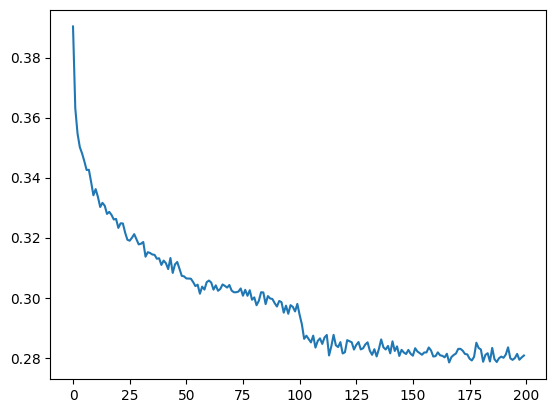

In [19]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1));

In [20]:
# Sample from the model
for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # Forward pass though the neural net
      logits = model(torch.tensor([context]))
      probs = F.softmax(logits, dim=1)
      # Sample from the distribution
      ix = torch.multinomial(probs, num_samples=1).item()
      # Shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # As soon as we sample the special '.' token, break
      if ix == 0:
        break

    # Decode and print the generated words (Inferences)
    print(''.join(itos[i] for i in out))

vanthuri.
dosdlyne.
alayanthan.
vijayakesh.
boochrer.
varaalan.
pattpadatre.
janathas.
aziruchandarupin.
mreena.
akalaiyadaye.
semvind.
arunna.
malayanta.
harendrakankara.
ganamya.
monga.
immathurvi.
amoda.
jivanesh.


In [21]:
def get_state(model):
    state = {}
    for i, layer in enumerate(model.layers):
        for name in ['weight', 'bias', 'gamma', 'beta', 'running_mean', 'running_var']:
            t = getattr(layer, name, None)
            if t is not None:
                state[f'{i}.{name}'] = t.detach().cpu()
    return state

torch.save({
    'state': get_state(model),
    'itos': itos,
    'block_size': block_size,
}, 'wavenet.pt')